# Figure S12: Credible-set sizes and differences from AFR

Credible-set size distributions and mean-size differences relative to AFR.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig1_finemapping](../../preparation/Fig1/04_finemapping.R): Aggregate each raw credible set once, preserve its source size, compute maximum PIP and tie count, and prepare main D/E plus S11 inputs.
- [fig1_supplements](../../preparation/Fig1/05_supplements.R): Prepare exact S12 size summaries and gene-cluster analytic contrasts plus S13 bounded PIP density grids and summaries.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read source credible sets for all populations

Aggregate variant rows to one credible set and one lead PIP per set. Include the current EAS eQTL input.


In [2]:
# Pure transformations used by the current Figure 1 preparation steps.
# All identifiers are stable gene IDs. Source q values are not recalculated.
fig1_assert_local_input <- function(path) {
  if (grepl("^(gs|s3|https?)://", path)) stop("Input localization error: unresolved cloud URI.", call. = FALSE)
  if (!file.exists(path) || file.access(path, 4) != 0) stop("Missing or unreadable local input: ", path, call. = FALSE)
  invisible(path)
}

fig1_read_gene_gtf <- function(path) {
  fig1_assert_local_input(path)
  connection <- if (grepl("\\.gz$", path)) gzfile(path, "rt") else file(path, "rt")
  on.exit(close(connection))
  chunks <- list()
  repeat {
    lines <- readLines(connection, n = 50000L, warn = FALSE)
    if (!length(lines)) break
    lines <- lines[str_detect(lines, "^[^#][^\\t]*\\t[^\\t]*\\tgene\\t")]
    if (length(lines)) chunks[[length(chunks) + 1L]] <- read_tsv(I(paste(lines, collapse = "\n")),
      col_names = c("chromosome", "source", "feature", "start", "end", "score", "strand", "frame", "attributes"),
      col_types = cols(.default = col_character()), quote = "", progress = FALSE)
  }
  genes <- bind_rows(chunks) %>% transmute(
    gene_id = str_extract(str_match(attributes, 'gene_id "([^"]+)"')[, 2], "ENSG[0-9]+"),
    gene_name = str_match(attributes, 'gene_name "([^"]+)"')[, 2],
    gene_type = str_match(attributes, 'gene_type "([^"]+)"')[, 2],
    chromosome, start = as.integer(start), end = as.integer(end), strand)
  stopifnot(nrow(genes) > 0, !anyNA(genes), !anyDuplicated(genes$gene_id))
  genes
}

fig1_ukbb_target_map <- function(gene_ref, hgnc, panel) {
  hgnc <- hgnc %>% filter(status == "Approved", str_detect(ensembl_gene_id, "^ENSG[0-9]+$"))
  approved <- hgnc %>% transmute(gene_name = symbol, gene_id = ensembl_gene_id,
    approved_symbol = symbol, mapping_source = "HGNC approved symbol", priority = 1L)
  previous <- hgnc %>% separate_longer_delim(prev_symbol, delim = "|") %>%
    filter(!is.na(prev_symbol), prev_symbol != "") %>%
    transmute(gene_name = prev_symbol, gene_id = ensembl_gene_id, approved_symbol = symbol,
      mapping_source = "HGNC previous symbol", priority = 2L)
  aliases <- hgnc %>% separate_longer_delim(alias_symbol, delim = "|") %>%
    filter(!is.na(alias_symbol), alias_symbol != "") %>%
    transmute(gene_name = alias_symbol, gene_id = ensembl_gene_id, approved_symbol = symbol,
      mapping_source = "HGNC alias", priority = 4L)
  gencode <- gene_ref %>% filter(gene_type == "protein_coding") %>%
    transmute(gene_name, gene_id, approved_symbol = gene_name,
      mapping_source = "GENCODE v48 exact protein symbol", priority = 0L)
  best <- bind_rows(approved, previous, gencode, aliases) %>% distinct() %>%
    group_by(gene_name) %>% filter(priority == min(priority)) %>% ungroup()
  ambiguous <- best %>% group_by(gene_name) %>%
    filter(n_distinct(gene_id) > 1L, first(priority) != 0L) %>% ungroup()
  mapping <- best %>% anti_join(ambiguous %>% distinct(gene_name), by = "gene_name") %>%
    arrange(gene_name, priority) %>% distinct(gene_name, gene_id, .keep_all = TRUE)
  protein_names <- hgnc %>% select(symbol, ensembl_gene_id, uniprot_ids) %>%
    separate_longer_delim(uniprot_ids, delim = "|") %>% filter(!is.na(uniprot_ids)) %>%
    group_by(uniprot_ids) %>% filter(n_distinct(symbol) == 1L) %>% ungroup()
  protein_identity <- panel %>% inner_join(protein_names,
    by = c("uniprot_id" = "uniprot_ids"), relationship = "many-to-many") %>%
    group_by(gene_name) %>% filter(n_distinct(symbol) == 1L) %>% ungroup() %>%
    left_join(gencode %>% select(current_symbol = gene_name, current_gene_id = gene_id),
      by = c("symbol" = "current_symbol"), relationship = "many-to-many") %>%
    transmute(gene_name, gene_id = coalesce(current_gene_id, ensembl_gene_id),
      approved_symbol = symbol,
      mapping_source = "UKBB ST3 UniProt identity; GENCODE protein ID where available", priority = -1L) %>% distinct()
  mapping <- bind_rows(mapping %>% anti_join(protein_identity %>% distinct(gene_name), by = "gene_name"),
                        protein_identity)
  list(map = mapping, ambiguous = ambiguous, protein_identity = protein_identity)
}

fig1_ukbb_cis_targets <- function(st9, mapping) {
  targets <- st9 %>% filter(`cis/trans` == "cis") %>%
    transmute(assay_target = `Assay Target`, reference_symbol = `cis gene`,
      variant_annotation_gene_id = `Ensembl gene ID`) %>%
    separate_longer_delim(reference_symbol, delim = ",") %>%
    mutate(reference_symbol = str_trim(reference_symbol)) %>%
    left_join(mapping %>% distinct(gene_name, gene_id),
      by = c("reference_symbol" = "gene_name"), relationship = "many-to-many") %>% distinct()
  list(mapped = filter(targets, !is.na(gene_id)), unresolved = filter(targets, is.na(gene_id)), audit = targets)
}

fig1_classify_novelty <- function(raw, genes, known, measured_ids = character()) {
  stopifnot(!anyDuplicated(raw[c("assay", "phenotype_id")]), !anyDuplicated(genes$gene_id))
  x <- raw %>% mutate(gene_id = str_extract(phenotype_id, "ENSG[0-9]+")) %>%
    left_join(genes, by = "gene_id", relationship = "many-to-one") %>%
    left_join(known %>% group_by(assay, gene_id) %>%
      summarise(prior_studies = paste(sort(unique(study)), collapse = ";"), .groups = "drop"),
      by = c("assay", "gene_id"), relationship = "many-to-one") %>%
    mutate(significant = as.double(source_qval) < .05,
      paper_biotype_retained = !is.na(gene_type) & !str_detect(gene_type, "pseudo|IG|TEC|TR"),
      pQTL_lncRNA_excluded_by_paper = assay == "pQTL" & gene_type == "lncRNA",
      previously_reported = !is.na(prior_studies),
      novel_in_paper = significant & !previously_reported & paper_biotype_retained &
        !pQTL_lncRNA_excluded_by_paper,
      novel_for_figure = novel_in_paper & gene_type != "artifact",
      group = case_when(gene_type == "protein_coding" ~ "Protein-Coding",
                        gene_type == "lncRNA" ~ "lncRNA", TRUE ~ "non-coding RNA"),
      type = recode(assay, eQTL = "eGene", sQTL = "sGene", pQTL = "pGene"),
      ukbb_measured = if_else(assay == "pQTL", gene_id %in% measured_ids, NA),
      novelty_context = case_when(!novel_for_figure ~ "Not selected as novel",
        assay != "pQTL" ~ "Absent from the specified significant blood-reference gene sets",
        ukbb_measured ~ "Measured by UKBB; no significant cis association in ST9",
        TRUE ~ "Not represented by a mapped UKBB ST3 protein target"))
  stopifnot(!anyNA(x$gene_id), !anyNA(x$significant), !anyNA(x$novel_for_figure))
  x
}

fig1_credible_sets <- function(variants, assay_name, population_name) {
  stopifnot(nrow(variants) > 0, !anyNA(variants), all(is.finite(variants$pip)),
    all(between(variants$pip, 0, 1)), all(variants$cs_size >= 1),
    all(variants$cs_size == as.integer(variants$cs_size)),
    all(str_remove(variants$cs_id, "_L[0-9]+$") == variants$molecular_trait_id))
  consistency <- variants %>% group_by(cs_id) %>%
    summarise(n_traits = n_distinct(molecular_trait_id), n_sizes = n_distinct(cs_size), .groups = "drop")
  stopifnot(all(consistency$n_traits == 1L), all(consistency$n_sizes == 1L))
  variants %>% group_by(cs_id) %>%
    summarise(molecular_trait_id = first(molecular_trait_id), cs_size = first(cs_size),
      lead_pip = max(pip), lead_variant = first(variant[pip == max(pip)]),
      n_tied_lead_variants = n_distinct(variant[pip == max(pip)]), .groups = "drop") %>%
    mutate(assay = assay_name, population = population_name)
}

fig1_finemapping_summaries <- function(sets) {
  traits <- sets %>% distinct(assay, population, cs_id, molecular_trait_id) %>%
    count(assay, population, molecular_trait_id, name = "number_credible_sets")
  lead_summary <- sets %>% group_by(assay, population) %>% summarise(n_cs = n(),
    median_lead_pip = median(lead_pip), mean_lead_pip = mean(lead_pip),
    n_pip_above_09 = sum(lead_pip > .9), pct_pip_above_09 = 100 * mean(lead_pip > .9), .groups = "drop")
  curves <- map_dfr(1:5, function(k) traits %>% filter(population == "COMB") %>% group_by(assay) %>%
    summarise(k = k, numerator = sum(number_credible_sets >= k), denominator = n(),
      proportion = mean(number_credible_sets >= k), .groups = "drop"))
  list(traits = traits, lead_summary = lead_summary, curves = curves)
}

fig1_category_counts <- function(membership, categories) {
  long <- membership %>% select(assay, gene_id, gene_name, all_of(categories)) %>%
    distinct() %>% pivot_longer(all_of(categories), names_to = "category", values_to = "member")
  counts <- long %>% group_by(assay, category) %>%
    summarise(n_genes = n_distinct(gene_id[member %in% TRUE]), unknown = sum(is.na(member)), .groups = "drop")
  lists <- long %>% filter(member %in% TRUE) %>% distinct(assay, category, gene_id, gene_name)
  list(counts = counts, lists = lists,
       distinct = lists %>% group_by(category) %>% summarise(n_genes = n_distinct(gene_id), .groups = "drop"))
}

fig1_go_descendants <- function(nodes, edges, root) {
  edges <- edges %>% filter(child %in% nodes$go_id, parent %in% nodes$go_id,
    predicate %in% c("is_a", "http://purl.obolibrary.org/obo/BFO_0000050"))
  seen <- root
  repeat {
    expanded <- union(seen, edges$child[edges$parent %in% seen])
    if (length(expanded) == length(seen)) break
    seen <- expanded
  }
  seen
}

# The analytic contrast uses stable genes as clusters. Shared-gene covariance
# enters through the difference between each group and AFR contribution.
fig1_size_contrasts <- function(cs, assays, groups) {
  cs <- cs %>% mutate(gene_id = str_extract(cs_id, "ENSG[0-9]+"))
  stopifnot(!anyNA(cs$gene_id))
  gene_sums <- cs %>% group_by(assay, population, gene_id) %>%
    summarise(n_cs = n(), sum_size = sum(cs_size), .groups = "drop")
map_dfr(assays, function(a) {
  message("Calculate analytic differences and SEs: ", a)
  g <- gene_sums |> filter(assay == a)
  genes <- sort(unique(g$gene_id))
  G <- length(genes)
  N <- matrix(0, nrow = G, ncol = length(groups), dimnames = list(genes, groups))
  S <- N
  at <- cbind(match(g$gene_id, genes), match(as.character(g$population), groups))
  N[at] <- g$n_cs
  S[at] <- g$sum_size
  n_total <- colSums(N)
  mu <- colSums(S)/n_total
  residual <- S-sweep(N, 2, mu, `*`)
  contribution <- sweep(residual, 2, n_total, `/`)
  stopifnot(max(abs(colSums(contribution))) < 1e-10)
  covariance <- (G/(G-1))*crossprod(contribution)
  afr <- match("AFR", groups)
  delta_contribution <- sweep(contribution, 1, contribution[, afr], `-`)
  variance_delta <- (G/(G-1))*colSums(delta_contribution^2)
  # Independently express the same variance as V(group)+V(AFR)-2*Cov.
  second_variance <- diag(covariance)+covariance[afr, afr]-2*covariance[, afr]
  stopifnot(max(abs(variance_delta-second_variance)) < 1e-10)
  tibble(assay = a, population = groups, n_cs = n_total,
         n_cs_AFR = n_total[[afr]], mean_size = mu,
         AFR_mean_size = mu[[afr]], difference = mu-mu[[afr]],
         standard_error = sqrt(pmax(variance_delta, 0)),
         group_mean_SE = sqrt(diag(covariance)),
         AFR_mean_SE = sqrt(covariance[afr, afr]),
         covariance_with_AFR = covariance[, afr],
         gene_clusters_in_assay = G, n_genes_group = colSums(N > 0),
         n_genes_AFR = sum(N[, afr] > 0),
         n_shared_genes_with_AFR = colSums((N > 0) & (N[, afr] > 0)))
}) |>
  mutate(assay = factor(assay, levels = assays),
         population = factor(population, levels = groups),
         lower_1SE = difference-standard_error,
         upper_1SE = difference+standard_error)
}

message("Figure 1 transformations defined.")

fig1_groups <- c("COMB", "AFR", "AMR", "EUR", "SAS", "EAS", "MID")


Figure 1 transformations defined.


## Read source fine-mapping rows and reduce them to credible sets

Each input row describes a variant in a credible set. The maximum PIP defines the lead PIP.
The current EAS eQTL file can be gzip CSV with a .tsv suffix. The reader checks its file signature.


In [3]:
assays <- c("eQTL", "sQTL", "pQTL")
groups <- fig1_groups
read_selected <- function(path, include_group = FALSE) {
  # The current EAS eQTL download is gzip CSV with a .tsv filename.
  # Inspect the magic bytes. Copy to a temporary gzip filename when required.
  connection <- file(path, "rb")
  magic <- readBin(connection, "raw", n = 2L)
  close(connection)
  input_path <- path
  if (identical(magic, as.raw(c(31, 139))) && !str_detect(path, "\\.gz$")) {
    input_path <- tempfile(fileext = ".csv.gz")
    stopifnot(file.copy(path, input_path))
    on.exit(unlink(input_path))
  }
  data.table::fread(input_path, select = c("molecular_trait_id", "cs_id", "cs_size", "variant", "pip",
    if (include_group) "group"), showProgress = FALSE, nThread = 2L) %>% as_tibble()
}
inputs <- crossing(assay = assays, population = groups) %>%
  mutate(relative = case_when(
    assay == "eQTL" ~ paste0("Fig1Data/PopulationLevelFinemapping/eQTL/AoU_", population, "_9k_eQTL_SusieMerged.tsv.gz"),
    assay == "sQTL" ~ paste0("Fig1Data/PopulationLevelFinemapping/sQTL/AoU_", population, "_9k_sQTL_SusieMerged.annotated.tsv"),
    TRUE ~ "Fig1Data/PopulationLevelFinemapping/pQTL/pQTL_fm_data_10k.tsv"))
inputs$path <- map2_chr(seq_len(nrow(inputs)), inputs$relative, function(i, relative) {
  if (inputs$assay[[i]] == "eQTL" && inputs$population[[i]] == "EAS") {
    prep_input_file("QTL_FIG1_EAS_EQTL_FILE", "input",
      "Fig1Data/PopulationLevelFinemapping/eQTL/EAS_20261102.eQTL_SusieMerged.tsv")
  } else prep_input("input", relative)
})
protein_rows <- read_selected(inputs$path[inputs$assay == "pQTL"][[1]], include_group = TRUE)
sets <- pmap_dfr(inputs, function(assay, population, relative, path) {
  message("Figure 1: Aggregate raw credible sets: ", assay, " / ", population)
  d <- if (assay == "pQTL") filter(protein_rows, group == population) else read_selected(path, assay == "sQTL")
  if (assay == "sQTL") stopifnot(all(d$group == paste0("AoU_", population, "_9k_sQTL")))
  fig1_credible_sets(d %>% select(molecular_trait_id, cs_id, cs_size, variant, pip), assay, population)
}) %>% mutate(assay = factor(assay, levels = assays), population = factor(population, levels = groups))
stopifnot(nrow(distinct(sets, assay, population)) == length(assays) * length(groups),
          !anyDuplicated(sets[c("assay", "population", "cs_id")]))

rm(protein_rows)
invisible(gc())
summary_data <- fig1_finemapping_summaries(sets)
traits <- summary_data$traits
message("Calculated ", nrow(sets), " credible sets from source variant rows.")

labels <- c(COMB = "Combined", AFR = "AFR", AMR = "AMR", EUR = "EUR", SAS = "SAS", EAS = "EAS", MID = "MID")
cs <- sets %>% select(assay, population, cs_id, cs_size)


Figure 1: Aggregate raw credible sets: eQTL / AFR


Figure 1: Aggregate raw credible sets: eQTL / AMR


Figure 1: Aggregate raw credible sets: eQTL / COMB


Figure 1: Aggregate raw credible sets: eQTL / EAS


Figure 1: Aggregate raw credible sets: eQTL / EUR


Figure 1: Aggregate raw credible sets: eQTL / MID


... (12 outputs left out)

Figure 1: Aggregate raw credible sets: sQTL / EUR


Figure 1: Aggregate raw credible sets: sQTL / MID


Figure 1: Aggregate raw credible sets: sQTL / SAS


Calculated 457883 credible sets from source variant rows.


## Calculate size distributions and draw their boxplots

The boxplot uses log10 sizes, retains all outliers, and shows the supplied UKBB pQTL reference mean of 9.7 variants.


In [4]:
summary <- cs |>
  group_by(assay, population) |>
  summarize(n_cs = n(), mean_size = mean(cs_size),
            min_size = min(cs_size), q1 = quantile(cs_size, .25),
            median_size = median(cs_size), q3 = quantile(cs_size, .75),
            max_size = max(cs_size),
            log_q1 = quantile(log10(cs_size), .25),
            log_median = median(log10(cs_size)),
            log_q3 = quantile(log10(cs_size), .75), .groups = "drop") |>
  mutate(log_fence_low = log_q1-1.5*(log_q3-log_q1),
         log_fence_high = log_q3+1.5*(log_q3-log_q1))

whiskers <- cs |>
  left_join(summary |> select(assay, population, log_fence_low, log_fence_high),
            by = c("assay", "population")) |>
  mutate(outlier = log10(cs_size) < log_fence_low | log10(cs_size) > log_fence_high) |>
  group_by(assay, population) |>
  summarize(whisker_low = min(cs_size[!outlier]),
            whisker_high = max(cs_size[!outlier]), n_outliers = sum(outlier), .groups = "drop")

summary <- summary |> left_join(whiskers, by = c("assay", "population"))

order_check <- summary |> arrange(assay, population) |> group_by(assay) |>
  summarize(increasing_mean_size = all(diff(mean_size) >= 0), .groups = 'drop')

stopifnot(all(order_check$increasing_mean_size))

fills <- c(COMB = '#CF597E', AFR = '#C8D892', AMR = '#7FC385', EAS = '#ECA676', EUR = '#30AC86', SAS = '#EBCE8D', MID = '#E47D72')

lines <- c(COMB = '#822E4A', AFR = '#6F7F20', AMR = '#39743F', EAS = '#9B5900', EUR = '#06664C', SAS = '#917502', MID = '#9A3B2D')

p <- ggplot(cs, aes(population, cs_size, fill = population, colour = population)) +
  geom_boxplot(width = .58, linewidth = .35, outlier.size = .45,
               outlier.stroke = .1, outlier.alpha = .8, show.legend = FALSE) +
  facet_wrap(vars(assay), ncol = 1, axes = "all", axis.labels = "all") +
  scale_fill_manual(values = fills, guide = "none") +
  scale_colour_manual(values = lines, guide = "none") +
  scale_x_discrete(limits = groups,
                   labels = c(COMB = "Combined", AFR = "AFR", AMR = "AMR", EAS = "EAS", EUR = "EUR", SAS = "SAS", MID = "MID"),
                   expand = expansion(add = .65)) +
  scale_y_log10(limits = c(.8, 3300), breaks = c(1, 10, 100, 1000),
                labels = scales::label_comma(), expand = expansion(mult = 0)) +
  labs(x = "Population / analysis", y = "Credible set size (variants)") +
  theme_classic(base_size = 8, base_family = "Arial") +
  theme(axis.text = element_text(size = 7.5, colour = "#263B45"),
        axis.text.x = element_text(margin = margin(t = 3)),
        axis.title = element_text(size = 8),
        axis.title.x = element_text(margin = margin(t = 5)),
        axis.title.y = element_text(margin = margin(r = 5)),
        axis.line.x = element_blank(), axis.ticks.x = element_blank(),
        axis.line.y = element_line(linewidth = .3, colour = "#263B45"),
        axis.ticks.y = element_line(linewidth = .25, colour = "#263B45"),
        axis.ticks.length = unit(.8, "mm"),
        strip.background = element_blank(),
        strip.text = element_text(size = 9, face = "bold", margin = margin(b = 4)),
        panel.spacing.y = unit(4, "mm"),
        plot.margin = margin(3, 3, 3, 3, "mm"))

built <- ggplot_build(p)

observed <- built$data[[1]] |>
  transmute(assay = factor(assays[as.integer(PANEL)], levels = assays),
            population = factor(groups[group], levels = groups),
            observed_q1 = lower, observed_median = middle, observed_q3 = upper,
            observed_low = ymin, observed_high = ymax,
            observed_n_outliers = map_int(outliers, length))

check <- summary |> left_join(observed, by = c("assay", "population"))

stopifnot(nrow(check) == 21L,
          all(abs(check$log_q1-check$observed_q1) < 1e-10),
          all(abs(check$log_median-check$observed_median) < 1e-10),
          all(abs(check$log_q3-check$observed_q3) < 1e-10),
          all(abs(log10(check$whisker_low)-check$observed_low) < 1e-10),
          all(abs(log10(check$whisker_high)-check$observed_high) < 1e-10),
          all(check$n_outliers == check$observed_n_outliers))

ref <- tibble(assay = factor('pQTL', levels = assays),
              population = factor('EUR', levels = groups), reference_size = 9.7, label = 'UKBB pQTL')

eur_position <- match('EUR', groups)

p <- p +
  geom_segment(data = ref, aes(x = !!(eur_position + .03), xend = !!(eur_position + .24), y = 10.8, yend = 18),
               inherit.aes = FALSE, colour = 'black', linewidth = .25) +
  geom_point(data = ref, aes(population, reference_size), inherit.aes = FALSE,
             shape = 23, size = 2.1, stroke = .35, fill = '#4B9FC3', colour = '#186A91') +
  geom_text(data = ref, aes(x = !!(eur_position + .28), y = 22, label = label), inherit.aes = FALSE,
            family = 'Arial', fontface = 'bold', size = 7.5 / .pt, hjust = 0, colour = 'black')


## Calculate gene-cluster uncertainty for differences from AFR

Each gene contributes its set count and size sum. Subtract the AFR influence within each gene to include covariance.


In [5]:
cs <- cs |> mutate(gene_id = str_extract(cs_id, 'ENSG[0-9]+'))

stopifnot(!anyNA(cs$gene_id))

gene_sums <- cs |>
  group_by(assay, population, gene_id) |>
  summarize(n_cs = n(), sum_size = sum(cs_size), .groups = "drop")

contrasts <- fig1_size_contrasts(cs, assays, groups)

expected <- cs |>
  group_by(assay, population) |>
  summarize(expected_mean = mean(cs_size), expected_n = n(), .groups = "drop")

checks <- contrasts |> left_join(expected, by = c("assay", "population"))

stopifnot(all(abs(checks$mean_size-checks$expected_mean) < 1e-10),
          all(checks$n_cs == checks$expected_n),
          all(contrasts$standard_error >= 0),
          all(contrasts$difference[contrasts$population == "AFR"] == 0),
          all(contrasts$standard_error[contrasts$population == "AFR"] == 0))

fills <- c(COMB = '#CF597E', AFR = '#C8D892', AMR = '#7FC385', EAS = '#ECA676', EUR = '#30AC86', SAS = '#EBCE8D', MID = '#E47D72')

lines <- c(COMB = '#822E4A', AFR = '#6F7F20', AMR = '#39743F', EAS = '#9B5900', EUR = '#06664C', SAS = '#917502', MID = '#9A3B2D')

bdata <- contrasts |>
  filter(population != "AFR") |>
  mutate(population = factor(population, levels = rev(setdiff(groups, 'AFR'))))

plot_b <- ggplot(bdata, aes(y = population, x = difference, colour = population, fill = population)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "#70818A", linewidth = .3) +
  geom_errorbar(aes(xmin = lower_1SE, xmax = upper_1SE),
                 orientation = "y", width = .32, linewidth = .4, show.legend = FALSE) +
  geom_point(shape = 21, size = 1.6, stroke = .35, show.legend = FALSE) +
  facet_grid(~ assay) +
  scale_colour_manual(values = lines, guide = "none") +
  scale_fill_manual(values = fills, guide = "none") +
  scale_y_discrete(labels = c(COMB = "Combined", AMR = "AMR", EAS = "EAS", EUR = "EUR", SAS = "SAS", MID = "MID"),
                   expand = expansion(add = .55)) +
  scale_x_continuous(limits = c(-5, 20), breaks = seq(-5, 20, 5),
                     expand = expansion(mult = 0)) +
  labs(x = "Mean credible-set size difference vs AFR (variants)", y = NULL) +
  theme_classic(base_size = 8, base_family = "Arial") +
  theme(axis.text = element_text(size = 7.5, colour = "#263B45"),
        axis.text.x = element_text(margin = margin(t = 3)),
        axis.text.y = element_text(margin = margin(r = 3)),
        axis.title.x = element_text(size = 8, margin = margin(t = 5)),
        axis.line.y = element_blank(), axis.ticks.y = element_blank(),
        axis.line.x = element_line(linewidth = .3, colour = "#263B45"),
        axis.ticks.x = element_line(linewidth = .25, colour = "#263B45"),
        axis.ticks.length = unit(.8, "mm"),
        strip.background = element_blank(),
        strip.text = element_text(size = 9, face = "bold", margin = margin(b = 5)),
        panel.spacing.x = unit(4, "mm"),
        plot.margin = margin(3, 3, 3, 3, "mm"))

built_b <- ggplot_build(plot_b)

stopifnot(nrow(built_b$data[[2]]) == 18L, nrow(built_b$data[[3]]) == 18L,
          all(bdata$lower_1SE > -5), all(bdata$upper_1SE < 20),
          !anyNA(built_b$data[[2]]$xmin), !anyNA(built_b$data[[2]]$xmax))

plot_a <- p


Calculate analytic differences and SEs: eQTL


Calculate analytic differences and SEs: sQTL


Calculate analytic differences and SEs: pQTL


## Assemble the size and contrast panels


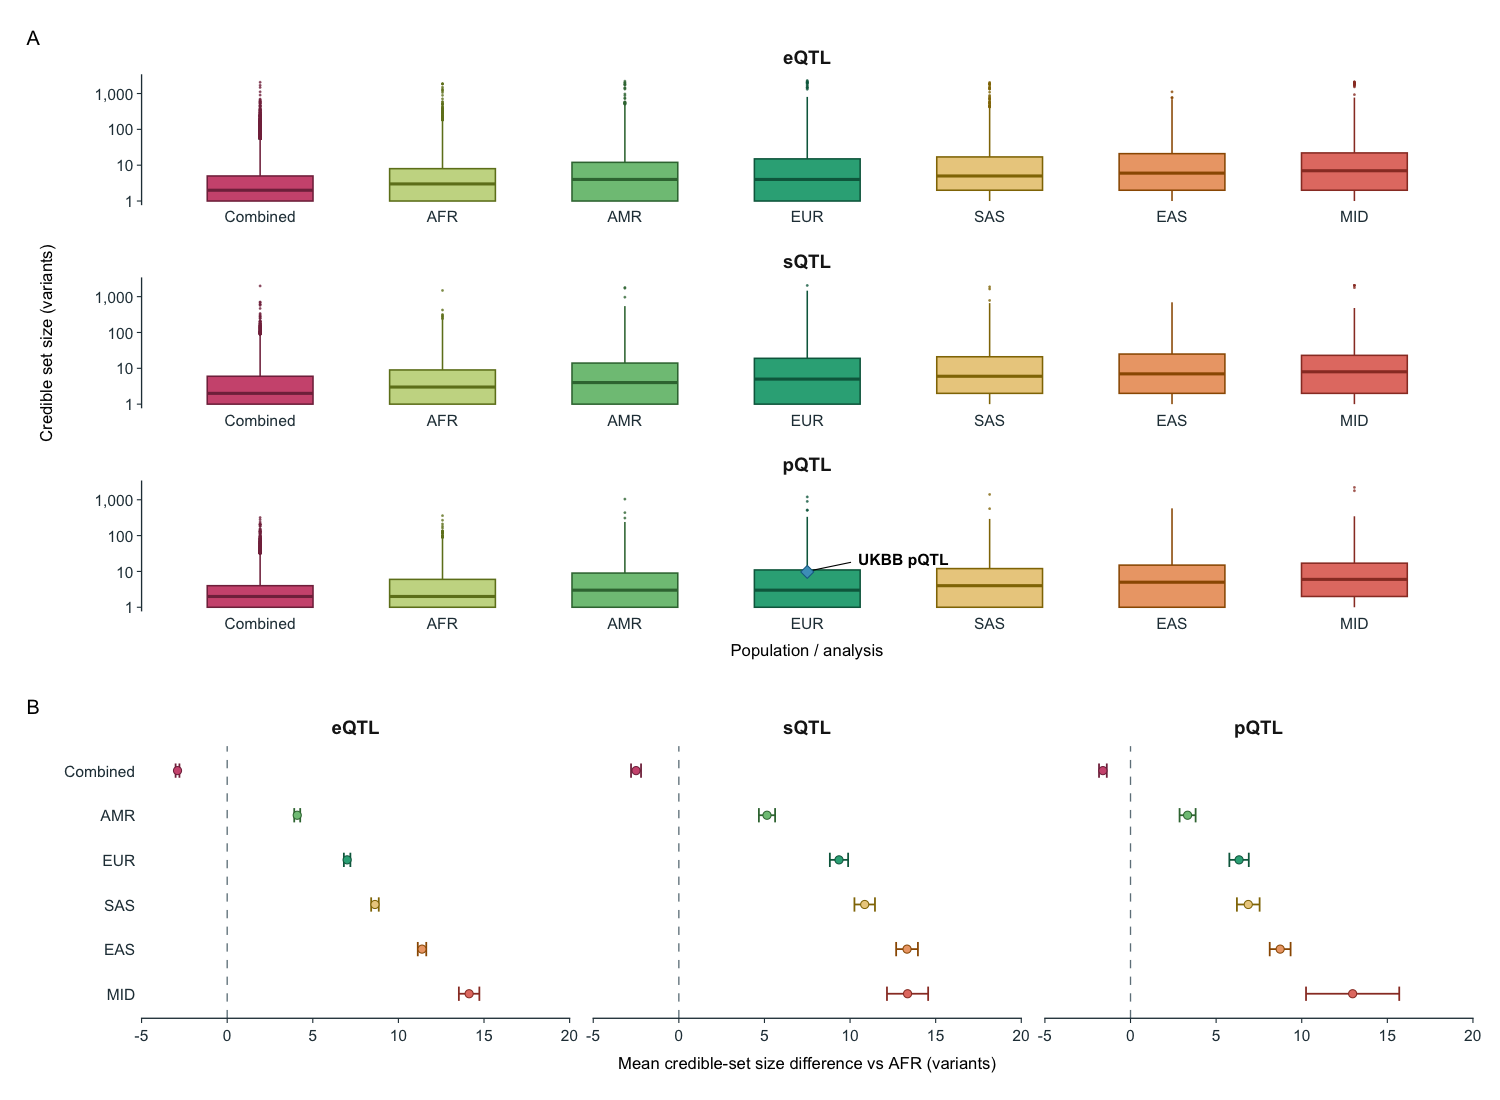

In [6]:
figure <- plot_a / plot_b + plot_layout(heights = c(124, 63)) + plot_annotation(tag_levels = "A")
print(figure)


## Save aggregate outputs


In [7]:
save_plot(figure, "supplements/S12", 184, 195)
write_tsv(cs %>% count(assay, population, cs_size, name = "credible_sets"),
          output_file("supplements/S12_size_frequencies.tsv"))
write_tsv(contrasts, output_file("supplements/S12_AFR_contrasts.tsv"))


Export aggregate plot: supplements/S12
